# 02 — Modèle de Black-Scholes et Grecques (S2)

`d1 = [ln(S/K) + (r + σ²/2)T] / (σ√T)`, `d2 = d1 − σ√T`

Call `= S·N(d1) − K·e^(−rT)·N(d2)` ; Put `= K·e^(−rT)·N(−d2) − S·N(−d1)`

Delta `= N(d1)` ; Gamma `= φ(d1)/(Sσ√T)` ; Vega `= S·φ(d1)·√T` ; Theta (call) `= −Sφ(d1)σ/(2√T) − rK·e^(−rT)·N(d2)` ; Rho (call) `= K·T·e^(−rT)·N(d2)`.

Unités (`CONVENTIONS.md`) : `T` en années, `r` continu, `σ` annualisée ; Theta par an, Vega pour 1,00 de σ, Rho pour 1,00 de r.

In [1]:
import sys, os
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
os.makedirs("../docs/figures", exist_ok=True)
import json
from pricing import bs_price, greeks, put_call_parity_gap

## 1. Cas de référence (S = K = 100, T = 1, r = 5 %, σ = 20 %)
Les `assert` comparent aux valeurs du cours et de `CONVENTIONS.md`.

In [2]:
S, K, T, r, s = 100.0, 100.0, 1.0, 0.05, 0.20
C, P = bs_price(S, K, T, r, s, "call"), bs_price(S, K, T, r, s, "put")
g = greeks(S, K, T, r, s, "call")
print(f"call {C:.4f} | put {P:.4f}"); print({k: round(float(v), 4) for k, v in g.items()})
assert abs(C - 10.4506) < 1e-3 and abs(P - 5.5735) < 1e-3
assert abs(g["delta"] - 0.6368) < 1e-3 and abs(g["vega"] - 37.524) < 1e-2 and abs(g["theta"] + 6.414) < 1e-2

call 10.4506 | put 5.5735
{'delta': 0.6368, 'gamma': 0.0188, 'vega': 37.524, 'theta': -6.414, 'rho': 53.2325}


## 2. Cas AAPL (paramètres du notebook 01)
`K` = cours arrondi (option à la monnaie), `T` = 30 jours. **`r` est une hypothèse saisie à la main** : remplacer par un taux sans risque sourcé (bon du Trésor à 3 mois) avant la présentation.

In [3]:
p = json.load(open("../docs/figures/parametres_aapl.json"))
S0, SIG = p["S0"], p["sigma_hist"]; K0, T0, R0 = round(S0), 30 / 365, 0.04   # R0 : hypothèse à sourcer
print("source des données :", p["source"])
for kind in ("call", "put"):
    print(kind, round(float(bs_price(S0, K0, T0, R0, SIG, kind)), 4), {k: round(float(v), 4) for k, v in greeks(S0, K0, T0, R0, SIG, kind).items()})

source des données : simulation GBM (données NON réelles)
call 2.5706 {'delta': 0.5131, 'gamma': 0.0617, 'vega': 10.7088, 'theta': -17.4832, 'rho': 3.7395}
put 2.5811 {'delta': -0.4869, 'gamma': 0.0617, 'vega': 10.7088, 'theta': -13.7355, 'rho': -3.9612}


## 3. Delta et Gamma en fonction du spot
Le Delta du call passe de 0 (loin hors de la monnaie) à 1 (loin dans la monnaie) ; le Gamma est maximal à la monnaie : c'est là que la couverture se périme le plus vite.

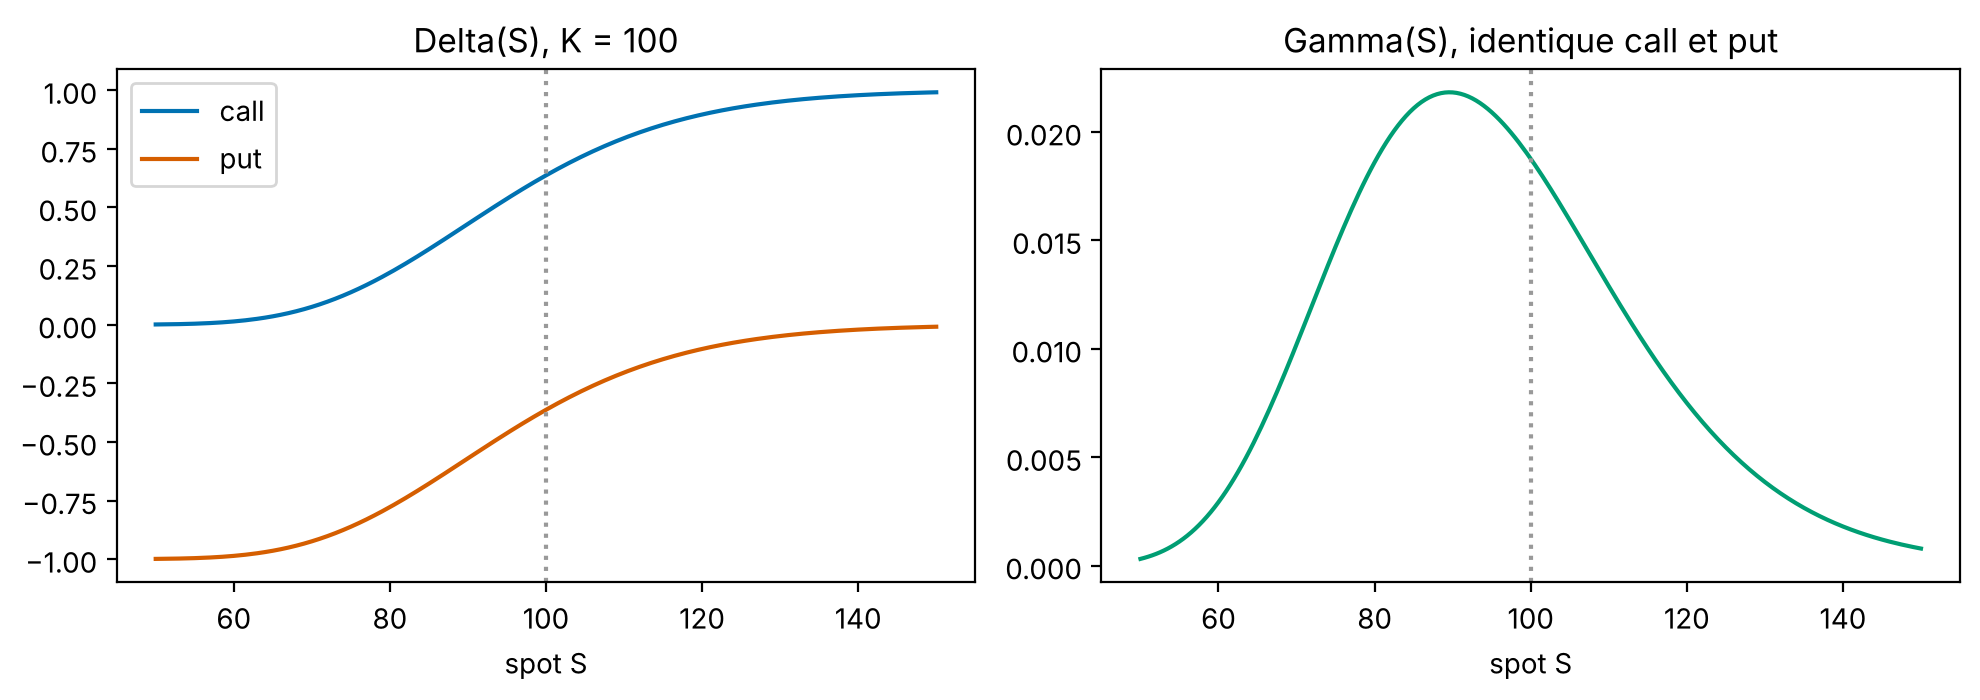

In [4]:
Sg = np.linspace(50, 150, 201)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for kind, col in (("call", "#0072B2"), ("put", "#D55E00")):
    ax[0].plot(Sg, greeks(Sg, K, T, r, s, kind)["delta"], color=col, label=kind)
ax[1].plot(Sg, greeks(Sg, K, T, r, s, "call")["gamma"], color="#009E73")
ax[0].set_title("Delta(S), K = 100"); ax[0].legend(); ax[1].set_title("Gamma(S), identique call et put")
for a in ax: a.axvline(K, color="#999999", ls=":"); a.set_xlabel("spot S")
fig.tight_layout(); fig.savefig("../docs/figures/fig_03_delta_gamma.png", dpi=150); plt.show()

## 4. Validation par différences finies
Chaque Grecque analytique est comparée à une dérivée numérique centrée `(V(x+h) − V(x−h)) / 2h` (Gamma : différence seconde). Theta = `−∂V/∂T`.

In [5]:
V = lambda S_=S, T_=T, r_=r, s_=s: bs_price(S_, K, T_, r_, s_, "call")
h = 1e-3
num = {"delta": (V(S_=S+h) - V(S_=S-h)) / (2*h),
       "gamma": (V(S_=S+h) - 2*V() + V(S_=S-h)) / h**2,
       "vega":  (V(s_=s+1e-5) - V(s_=s-1e-5)) / 2e-5,
       "theta": -(V(T_=T+1e-5) - V(T_=T-1e-5)) / 2e-5,
       "rho":   (V(r_=r+1e-5) - V(r_=r-1e-5)) / 2e-5}
tab = pd.DataFrame({"analytique": {k: float(g[k]) for k in num}, "numérique": num})
tab["écart relatif"] = (tab["analytique"] - tab["numérique"]).abs() / tab["analytique"].abs()
print(tab.to_string(float_format=lambda x: f"{x:.6g}"))
assert (tab["écart relatif"] < 1e-4).all()

       analytique  numérique  écart relatif
delta    0.636831   0.636831    1.29925e-10
gamma    0.018762   0.018762    8.32311e-07
vega       37.524     37.524    7.89956e-11
theta    -6.41403   -6.41403    2.48159e-11
rho       53.2325    53.2325    1.55853e-10


## 5. Parité call-put
`C − P = S − K·e^(−rT)` : l'écart doit être nul (aux arrondis machine près) sur toute une grille de paramètres.

In [6]:
grid = [(S_, K_, T_, r_, s_) for S_ in (80, 100, 120) for K_ in (90, 110) for T_ in (0.25, 1, 2) for r_ in (0.0, 0.05) for s_ in (0.1, 0.3)]
gaps = [put_call_parity_gap(bs_price(*x, "call"), bs_price(*x, "put"), x[0], x[1], x[2], x[3]) for x in grid]
print(f"{len(grid)} combinaisons, écart maximal = {max(abs(x) for x in gaps):.2e}"); assert max(abs(x) for x in gaps) < 1e-10

72 combinaisons, écart maximal = 2.13e-14


## 6. Sensibilité du prix à σ et à T
Le prix du call croît avec la volatilité (Vega > 0) et avec la durée (Theta < 0 : il perd de la valeur à mesure que l'échéance approche).

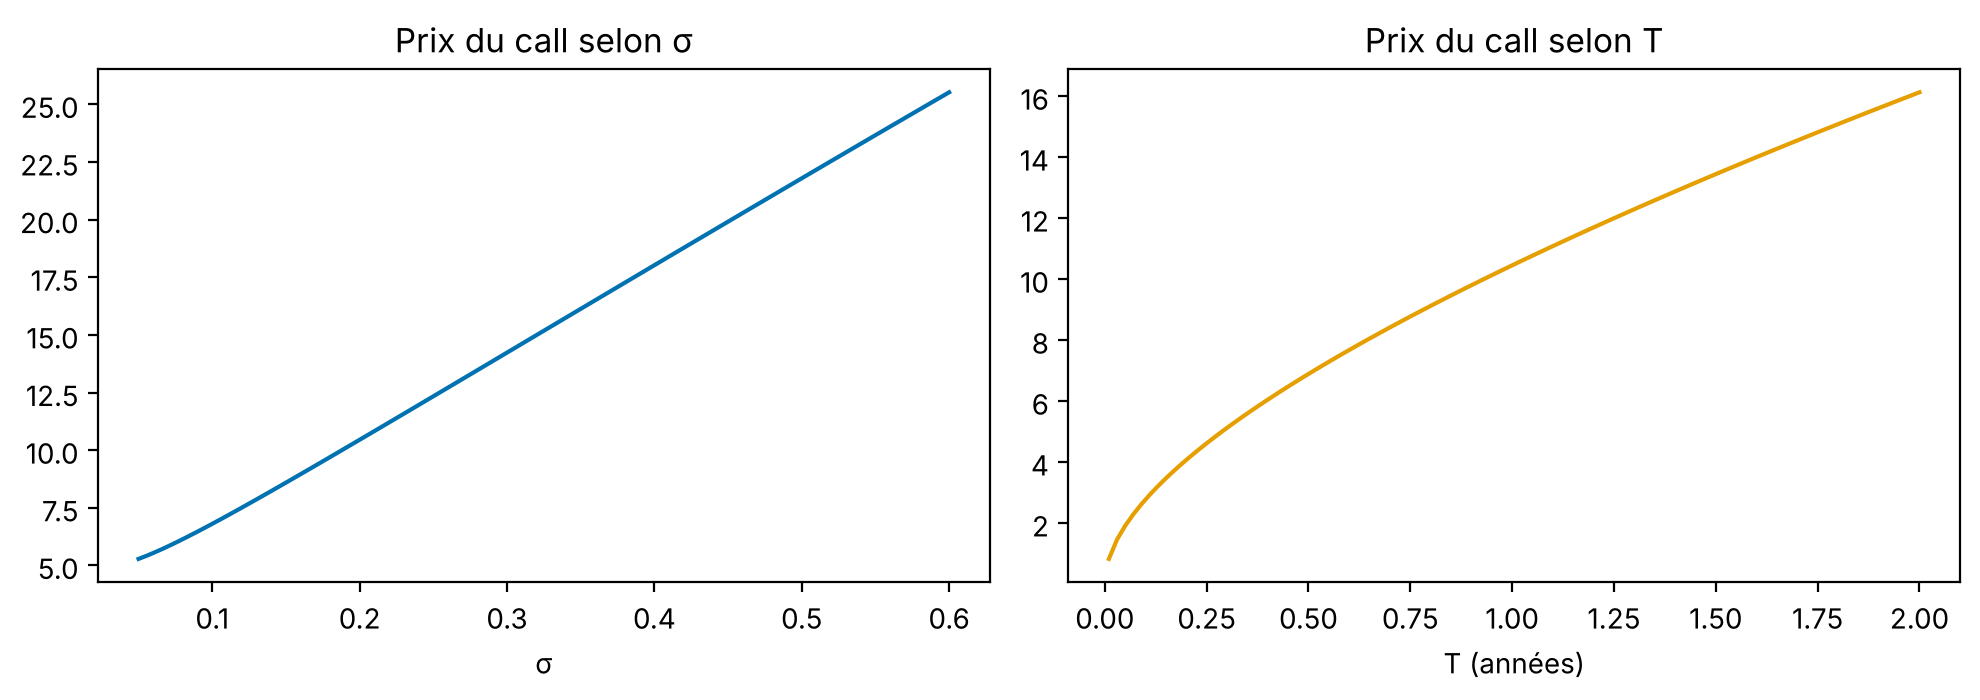

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
sg = np.linspace(0.05, 0.6, 100); Tg = np.linspace(0.01, 2, 100)
ax[0].plot(sg, bs_price(S, K, T, r, sg, "call"), color="#0072B2"); ax[0].set_xlabel("σ"); ax[0].set_title("Prix du call selon σ")
ax[1].plot(Tg, bs_price(S, K, Tg, r, s, "call"), color="#E69F00"); ax[1].set_xlabel("T (années)"); ax[1].set_title("Prix du call selon T")
fig.tight_layout(); fig.savefig("../docs/figures/fig_04_sensibilites.png", dpi=150); plt.show()

## 7. Récapitulatif
| Vérification | Résultat attendu |
|---|---|
| Cas de référence | call 10,4506 ; put 5,5735 ; Delta 0,6368 |
| Différences finies | écart relatif < 1e-4 sur les 5 Grecques |
| Parité call-put | écart < 1e-10 sur 72 combinaisons |
| Graphiques | Delta en S, Gamma maximal à la monnaie, prix croissant en σ et en T |

Ces contrôles sont aussi automatisés dans `tests/test_pricing.py` (pytest).